## Logs and epochs

In [1]:
!ls logs

root_stream_bim_2_shuffle_false_epochs_10_20261110_061713
root_stream_bim_2_shuffle_false_epochs_1_20261110_025522
root_stream_bim_2_shuffle_false_epochs_50_20261110_025958


## Logs exploration

In [2]:
import json
from pprint import pprint
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import matplotlib.colors as mcolors
from matplotlib.cm import ScalarMappable

In [3]:
FILE_E1 = 'logs/root_stream_bim_2_shuffle_false_epochs_1_20261110_025522/darshan_logs/strategy_stream_bim_2_shuffle_false_batchsize_64_epochs_1/satt_python3_id1749126-1749126_11-10-10523-5712789554778768917_1.darshan.json'
FILE_E2 = 'logs/root_stream_bim_2_shuffle_false_epochs_10_20261110_061713/darshan_logs/strategy_stream_bim_2_shuffle_false_batchsize_64_epochs_10/satt_python3_id1268171-1268171_11-10-22634-15246891861428475467_1.darshan.json'
FILE_E3 = 'logs/root_stream_bim_2_shuffle_false_epochs_50_20261110_025958/darshan_logs/strategy_stream_bim_2_shuffle_false_batchsize_64_epochs_50/satt_python3_id292472-292472_11-10-10799-13227730035649892144_1.darshan.json'

In [4]:
with open(FILE_E3) as file_e3:
    d = json.load(file_e3)
    file_e3.close()
pprint(d)

{'counters': {'DXT_POSIX': {},
              'POSIX': {'counters': ['POSIX_OPENS',
                                     'POSIX_FILENOS',
                                     'POSIX_DUPS',
                                     'POSIX_READS',
                                     'POSIX_WRITES',
                                     'POSIX_SEEKS',
                                     'POSIX_STATS',
                                     'POSIX_MMAPS',
                                     'POSIX_FSYNCS',
                                     'POSIX_FDSYNCS',
                                     'POSIX_RENAME_SOURCES',
                                     'POSIX_RENAME_TARGETS',
                                     'POSIX_RENAMED_FROM',
                                     'POSIX_MODE',
                                     'POSIX_BYTES_READ',
                                     'POSIX_BYTES_WRITTEN',
                                     'POSIX_MAX_BYTE_READ',
                                   

In [5]:
len(d['name_records'])

4160

In [6]:
name_records_raw = d['name_records']
name_records = name_records_raw.items()
name_records_list = list(name_records)
for i in range(10):
    print(name_records_list[i])

('16592106915301738621', 'heatmap:POSIX')
('14734109647742566553', '<STDIN>')
('15920181672442173319', '<STDOUT>')
('7238257241479193519', '<STDERR>')
('3989511027826779520', 'heatmap:STDIO')
('1183378753704768064', '/pscratch/sd/s/satt/sprints/myvenv/pyvenv.cfg')
('2753586021477318973', '/global/common/software/nersc/pe/conda-envs/26.8.0/python-3.13/nersc-python/lib/python3.13/os.py')
('14915634845633470549', '/global/common/software/nersc/pe/conda-envs/26.8.0/python-3.13/nersc-python/lib/python3.13/encodings/__init__.py')
('1279809238936159499', '/global/common/software/nersc/pe/conda-envs/26.8.0/python-3.13/nersc-python/lib/python3.13/encodings/aliases.py')
('14471277080580643569', '/global/common/software/nersc/pe/conda-envs/26.8.0/python-3.13/nersc-python/lib/python3.13/encodings/utf_8.py')


In [7]:
key_roots = [key for key, val in name_records if '_2.root' in val]
key_roots

['17582127309687269618']

In [8]:
for i in key_roots:
    print(name_records_raw[i])

/pscratch/sd/s/satt/sprints/data/roots/mc_normalized_rntuple_10M_2.root


In [9]:
key_py = [key for key, val in name_records if 'ff9.py' in val]
key_py 

['16476676496227311006']

In [10]:
for i in key_py:
    print(name_records_raw[i])

/pscratch/sd/s/satt/sprints/a_star_campaign/root/root_tr_ff9.py


In [11]:
DXT_POSIX_recs = d['records']['DXT_POSIX']
STDIO_recs = d['records']['STDIO']
POSIX_recs = d['records']['POSIX']

In [12]:
rows_from_POSIX = []
for i in POSIX_recs:
    ide = str(i['id'])
    if ide in key_py or ide in key_roots:
        print(i)
        rows_from_POSIX.append(i)

{'id': 16476676496227311006, 'rank': 0, 'counters': [5, 3, 0, 10, 0, 13, 19, -1, 0, 0, 0, 0, 0, 0, 209394, 0, 105375, 0, 5, 0, 5, 0, 0, 1, 8, 5, 1048576, 105376, 0, 5, 0, 0, 4, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 26953, 105376, 27480, 22632, 2, 1, 1, 1, 0, 0, 0, 0], 'fcounters': [1.3872308731079102, 1.3884718418121338, 0.0, 1.3890833854675293, 7.646143198013306, 7.646275997161865, 0.0, 7.64628529548645, 0.016895771026611328, 0.0, 0.009326696395874023, 0.011790990829467773, 0.0, 0.0, 0.0, 0.0, 0.0]}
{'id': 17582127309687269618, 'rank': 0, 'counters': [3, 0, 0, 925, 0, 5, 4, -1, 0, 0, 0, 0, 0, 0, 62557968847, 0, 1250866430, 0, 9, 0, 865, 0, 0, 406, 8, 922, 1048576, 198846222, 0, 8, 11, 0, 2, 0, 4, 400, 100, 400, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 42, 5303, 3780, 3775, 400, 50, 50, 50, 198846222, 127582302, 127395779, 127245188, 50, 50, 50, 50, 0, 0, 0, 0], 'fcounters': [21.36403203010559, 21.364248752593994, 0.0, 21.385591983795166, 28.08833408355713, 10

In [13]:
POSIX_counters = d['counters']['POSIX']['counters']
POSIX_counters

['POSIX_OPENS',
 'POSIX_FILENOS',
 'POSIX_DUPS',
 'POSIX_READS',
 'POSIX_WRITES',
 'POSIX_SEEKS',
 'POSIX_STATS',
 'POSIX_MMAPS',
 'POSIX_FSYNCS',
 'POSIX_FDSYNCS',
 'POSIX_RENAME_SOURCES',
 'POSIX_RENAME_TARGETS',
 'POSIX_RENAMED_FROM',
 'POSIX_MODE',
 'POSIX_BYTES_READ',
 'POSIX_BYTES_WRITTEN',
 'POSIX_MAX_BYTE_READ',
 'POSIX_MAX_BYTE_WRITTEN',
 'POSIX_CONSEC_READS',
 'POSIX_CONSEC_WRITES',
 'POSIX_SEQ_READS',
 'POSIX_SEQ_WRITES',
 'POSIX_RW_SWITCHES',
 'POSIX_MEM_NOT_ALIGNED',
 'POSIX_MEM_ALIGNMENT',
 'POSIX_FILE_NOT_ALIGNED',
 'POSIX_FILE_ALIGNMENT',
 'POSIX_MAX_READ_TIME_SIZE',
 'POSIX_MAX_WRITE_TIME_SIZE',
 'POSIX_SIZE_READ_0_100',
 'POSIX_SIZE_READ_100_1K',
 'POSIX_SIZE_READ_1K_10K',
 'POSIX_SIZE_READ_10K_100K',
 'POSIX_SIZE_READ_100K_1M',
 'POSIX_SIZE_READ_1M_4M',
 'POSIX_SIZE_READ_4M_10M',
 'POSIX_SIZE_READ_10M_100M',
 'POSIX_SIZE_READ_100M_1G',
 'POSIX_SIZE_READ_1G_PLUS',
 'POSIX_SIZE_WRITE_0_100',
 'POSIX_SIZE_WRITE_100_1K',
 'POSIX_SIZE_WRITE_1K_10K',
 'POSIX_SIZE_WRITE_10K

In [14]:
POSIX_fcounters = d['counters']['POSIX']['fcounters']
POSIX_fcounters

['POSIX_F_OPEN_START_TIMESTAMP',
 'POSIX_F_READ_START_TIMESTAMP',
 'POSIX_F_WRITE_START_TIMESTAMP',
 'POSIX_F_CLOSE_START_TIMESTAMP',
 'POSIX_F_OPEN_END_TIMESTAMP',
 'POSIX_F_READ_END_TIMESTAMP',
 'POSIX_F_WRITE_END_TIMESTAMP',
 'POSIX_F_CLOSE_END_TIMESTAMP',
 'POSIX_F_READ_TIME',
 'POSIX_F_WRITE_TIME',
 'POSIX_F_META_TIME',
 'POSIX_F_MAX_READ_TIME',
 'POSIX_F_MAX_WRITE_TIME',
 'POSIX_F_FASTEST_RANK_TIME',
 'POSIX_F_SLOWEST_RANK_TIME',
 'POSIX_F_VARIANCE_RANK_TIME',
 'POSIX_F_VARIANCE_RANK_BYTES']

In [15]:
len(rows_from_POSIX[0]['counters']) == len(POSIX_counters)

True

In [16]:
cross_counters_0 = dict(zip(POSIX_counters, rows_from_POSIX[0]['counters']))
pprint(cross_counters_0)

{'POSIX_ACCESS1_ACCESS': 26953,
 'POSIX_ACCESS1_COUNT': 2,
 'POSIX_ACCESS2_ACCESS': 105376,
 'POSIX_ACCESS2_COUNT': 1,
 'POSIX_ACCESS3_ACCESS': 27480,
 'POSIX_ACCESS3_COUNT': 1,
 'POSIX_ACCESS4_ACCESS': 22632,
 'POSIX_ACCESS4_COUNT': 1,
 'POSIX_BYTES_READ': 209394,
 'POSIX_BYTES_WRITTEN': 0,
 'POSIX_CONSEC_READS': 5,
 'POSIX_CONSEC_WRITES': 0,
 'POSIX_DUPS': 0,
 'POSIX_FASTEST_RANK': 0,
 'POSIX_FASTEST_RANK_BYTES': 0,
 'POSIX_FDSYNCS': 0,
 'POSIX_FILENOS': 3,
 'POSIX_FILE_ALIGNMENT': 1048576,
 'POSIX_FILE_NOT_ALIGNED': 5,
 'POSIX_FSYNCS': 0,
 'POSIX_MAX_BYTE_READ': 105375,
 'POSIX_MAX_BYTE_WRITTEN': 0,
 'POSIX_MAX_READ_TIME_SIZE': 105376,
 'POSIX_MAX_WRITE_TIME_SIZE': 0,
 'POSIX_MEM_ALIGNMENT': 8,
 'POSIX_MEM_NOT_ALIGNED': 1,
 'POSIX_MMAPS': -1,
 'POSIX_MODE': 0,
 'POSIX_OPENS': 5,
 'POSIX_READS': 10,
 'POSIX_RENAMED_FROM': 0,
 'POSIX_RENAME_SOURCES': 0,
 'POSIX_RENAME_TARGETS': 0,
 'POSIX_RW_SWITCHES': 0,
 'POSIX_SEEKS': 13,
 'POSIX_SEQ_READS': 5,
 'POSIX_SEQ_WRITES': 0,
 'POSIX_SIZE_

In [17]:
cross_counters_1 = dict(zip(POSIX_counters, rows_from_POSIX[1]['counters']))
pprint(cross_counters_1)

{'POSIX_ACCESS1_ACCESS': 198846222,
 'POSIX_ACCESS1_COUNT': 50,
 'POSIX_ACCESS2_ACCESS': 127582302,
 'POSIX_ACCESS2_COUNT': 50,
 'POSIX_ACCESS3_ACCESS': 127395779,
 'POSIX_ACCESS3_COUNT': 50,
 'POSIX_ACCESS4_ACCESS': 127245188,
 'POSIX_ACCESS4_COUNT': 50,
 'POSIX_BYTES_READ': 62557968847,
 'POSIX_BYTES_WRITTEN': 0,
 'POSIX_CONSEC_READS': 9,
 'POSIX_CONSEC_WRITES': 0,
 'POSIX_DUPS': 0,
 'POSIX_FASTEST_RANK': 0,
 'POSIX_FASTEST_RANK_BYTES': 0,
 'POSIX_FDSYNCS': 0,
 'POSIX_FILENOS': 0,
 'POSIX_FILE_ALIGNMENT': 1048576,
 'POSIX_FILE_NOT_ALIGNED': 922,
 'POSIX_FSYNCS': 0,
 'POSIX_MAX_BYTE_READ': 1250866430,
 'POSIX_MAX_BYTE_WRITTEN': 0,
 'POSIX_MAX_READ_TIME_SIZE': 198846222,
 'POSIX_MAX_WRITE_TIME_SIZE': 0,
 'POSIX_MEM_ALIGNMENT': 8,
 'POSIX_MEM_NOT_ALIGNED': 406,
 'POSIX_MMAPS': -1,
 'POSIX_MODE': 0,
 'POSIX_OPENS': 3,
 'POSIX_READS': 925,
 'POSIX_RENAMED_FROM': 0,
 'POSIX_RENAME_SOURCES': 0,
 'POSIX_RENAME_TARGETS': 0,
 'POSIX_RW_SWITCHES': 0,
 'POSIX_SEEKS': 5,
 'POSIX_SEQ_READS': 865,


In [18]:
cross_fcounters_0 = dict(zip(POSIX_fcounters, rows_from_POSIX[0]['fcounters']))
pprint(cross_fcounters_0)

{'POSIX_F_CLOSE_END_TIMESTAMP': 7.64628529548645,
 'POSIX_F_CLOSE_START_TIMESTAMP': 1.3890833854675293,
 'POSIX_F_FASTEST_RANK_TIME': 0.0,
 'POSIX_F_MAX_READ_TIME': 0.011790990829467773,
 'POSIX_F_MAX_WRITE_TIME': 0.0,
 'POSIX_F_META_TIME': 0.009326696395874023,
 'POSIX_F_OPEN_END_TIMESTAMP': 7.646143198013306,
 'POSIX_F_OPEN_START_TIMESTAMP': 1.3872308731079102,
 'POSIX_F_READ_END_TIMESTAMP': 7.646275997161865,
 'POSIX_F_READ_START_TIMESTAMP': 1.3884718418121338,
 'POSIX_F_READ_TIME': 0.016895771026611328,
 'POSIX_F_SLOWEST_RANK_TIME': 0.0,
 'POSIX_F_VARIANCE_RANK_BYTES': 0.0,
 'POSIX_F_VARIANCE_RANK_TIME': 0.0,
 'POSIX_F_WRITE_END_TIMESTAMP': 0.0,
 'POSIX_F_WRITE_START_TIMESTAMP': 0.0,
 'POSIX_F_WRITE_TIME': 0.0}


In [19]:
cross_fcounters_1 = dict(zip(POSIX_fcounters, rows_from_POSIX[1]['fcounters']))
pprint(cross_fcounters_1)

{'POSIX_F_CLOSE_END_TIMESTAMP': 10407.349228858948,
 'POSIX_F_CLOSE_START_TIMESTAMP': 21.385591983795166,
 'POSIX_F_FASTEST_RANK_TIME': 0.0,
 'POSIX_F_MAX_READ_TIME': 0.17986035346984863,
 'POSIX_F_MAX_WRITE_TIME': 0.0,
 'POSIX_F_META_TIME': 0.0005695819854736328,
 'POSIX_F_OPEN_END_TIMESTAMP': 28.08833408355713,
 'POSIX_F_OPEN_START_TIMESTAMP': 21.36403203010559,
 'POSIX_F_READ_END_TIMESTAMP': 10368.035229206085,
 'POSIX_F_READ_START_TIMESTAMP': 21.364248752593994,
 'POSIX_F_READ_TIME': 13.440268993377686,
 'POSIX_F_SLOWEST_RANK_TIME': 0.0,
 'POSIX_F_VARIANCE_RANK_BYTES': 0.0,
 'POSIX_F_VARIANCE_RANK_TIME': 0.0,
 'POSIX_F_WRITE_END_TIMESTAMP': 0.0,
 'POSIX_F_WRITE_START_TIMESTAMP': 0.0,
 'POSIX_F_WRITE_TIME': 0.0}


### Chrono

In [20]:
DXT_TRACE_PATH = 'logs/root_stream_bim_2_shuffle_false_epochs_50_20261110_025958/darshan_logs/strategy_stream_bim_2_shuffle_false_batchsize_64_epochs_50/satt_python3_id292472-292472_11-10-10799-13227730035649892144_1.darshan.dxt.txt'

In [21]:
with open(DXT_TRACE_PATH) as trace:
    content = trace.read()
print(content)

# darshan log version: 3.41
# compression method: ZLIB
# exe: /pscratch/sd/s/satt/sprints/myvenv/bin/python3 /pscratch/sd/s/satt/sprints/a_star_campaign/root/root_tr_ff9.py --data-path /pscratch/sd/s/satt/sprints/data/roots/mc_normalized_rntuple_10M_2.root --tree-name tree --target-col Label --strategy stream --no-shuffle --model M2 --batch-size 64 --epochs 50 --log-every 50000 
# uid: 114163
# jobid: 292472
# start_time: 1794308399
# start_time_asci: Tue Nov 10 05:59:59 2026
# end_time: 1794318808
# end_time_asci: Tue Nov 10 08:53:28 2026
# nprocs: 1
# run time: 10408.6869
# metadata: lib_ver = 3.5.0

# log file regions
# -------------------------------------------------------
# header: 1328 bytes (uncompressed)
# job data: 754 bytes (compressed)
# record table: 73728 bytes (compressed)
# POSIX module: 86012 bytes (compressed), ver=4
# STDIO module: 1885 bytes (compressed), ver=2
# DXT_POSIX module: 23416 bytes (compressed), ver=2
# HEATMAP module: 255 bytes (compressed), ver=1

# mou

In [22]:
keys_all = []
keys_all.append([key_roots, key_py])

In [23]:
keys_all = sum(sum(keys_all, []),[])
keys_all

['17582127309687269618', '16476676496227311006']

In [24]:
dxt_section = content.split("# DXT_POSIX module data")[1]
print(dxt_section)


# ***************************************************

# DXT, file_id: 1183378753704768064, file_name: /pscratch/sd/s/satt/sprints/myvenv/pyvenv.cfg
# DXT, rank: 0, hostname: nid006158
# DXT, number of threads: 1
# DXT, write_count: 0, read_count: 4
# DXT, mnt_pt: /pscratch, fs_type: lustre
# Module    Rank  Wt/Rd  Segment          Offset          Length    Start(s)      End(s)   Pthread-ID
 X_POSIX       0   read        0               0            6339      0.0620      0.0627   140218307675968
 X_POSIX       0   read        1            6339               0      0.0627      0.0627   140218307675968
 X_POSIX       0   read        2               0             387      0.0809      0.0809   140218307675968
 X_POSIX       0   read        3             387               0      0.0809      0.0809   140218307675968

# DXT, file_id: 6509654755798325290, file_name: /pscratch/sd/s/satt/sprints/myvenv/lib/python3.13/site-packages/distutils-precedence.pth
# DXT, rank: 0, hostname: nid006158
# D

In [25]:
blocks = re.split(
    r"(?=^# DXT, file_id:)",
    dxt_section,
    flags=re.MULTILINE
)

In [26]:
selected = []
for block in blocks:
    match = re.match(r"# DXT, file_id:\s*(\d+)", block.lstrip())

    if match and match.group(1) in {str(k) for k in keys_all}:
        selected.append(block.strip())
print(selected)

['# DXT, file_id: 16476676496227311006, file_name: /pscratch/sd/s/satt/sprints/a_star_campaign/root/root_tr_ff9.py\n# DXT, rank: 0, hostname: nid006158\n# DXT, number of threads: 1\n# DXT, write_count: 0, read_count: 10\n# DXT, mnt_pt: /pscratch, fs_type: lustre\n# Module    Rank  Wt/Rd  Segment          Offset          Length    Start(s)      End(s)   Pthread-ID\n X_POSIX       0   read        0               0           26953      1.3885      1.3890   140218307675968\n X_POSIX       0   read        1           26953               0      1.3890      1.3890   140218307675968\n X_POSIX       0   read        2               0          105376      1.4010      1.4128   140218307675968\n X_POSIX       0   read        3          105376               0      1.4128      1.4128   140218307675968\n X_POSIX       0   read        4               0           22632      1.4278      1.4318   140218307675968\n X_POSIX       0   read        5           22632               0      1.4318      1.4318   14

In [27]:
def parse_dxt_block(block):
    
    def extract(pattern):
        match = re.search(pattern, block, re.MULTILINE)
        if not match:
            raise ValueError(f"Missing field: {pattern}")
        return match.groups()
    
    file_id, file_name = extract(
        r"^# DXT, file_id:\s*(\d+), file_name:\s*(.+)$"
    )

    rank, hostname = extract(
        r"^# DXT, rank:\s*(-?\d+), hostname:\s*(.+)$"
    )

    (nthreads,) = extract(
        r"^# DXT, number of threads:\s*(\d+)$"
    )

    write_count, read_count = extract(
        r"^# DXT, write_count:\s*(\d+), read_count:\s*(\d+)$"
    )

    mnt_pt, fs_type = extract(
        r"^# DXT, mnt_pt:\s*(.*?), fs_type:\s*(.+)$"
    )

    rows = []

    for line in block.splitlines():
        cols = line.split()

        if not cols or cols[0] != "X_POSIX":
            continue
            
        if len(cols) != 9:
            raise ValueError(f"Invalid DXT row: {line}")
        
        module, row_rank, operation, segment, offset, length, start, end, pthread = cols

        rows.append({
            "module": module,
            "rank": int(row_rank),
            "operation": operation,
            "segment": int(segment),
            "offset": int(offset),
            "length": int(length),
            "start_s": float(start),
            "end_s": float(end),
            "pthread_id": None if pthread == "-1" else pthread
        })

    result = {
        "file_id": file_id,
        "file_name": file_name,
        "rank": int(rank),
        "hostname": hostname,
        "nthreads": int(nthreads),
        "write_count": int(write_count),
        "read_count": int(read_count),
        "mnt_pt": mnt_pt,
        "fs_type": fs_type,
        "rows": rows
    }

    return result

dxt_data = [parse_dxt_block(block) for block in selected]
        

In [28]:
dxt_data

[{'file_id': '16476676496227311006',
  'file_name': '/pscratch/sd/s/satt/sprints/a_star_campaign/root/root_tr_ff9.py',
  'rank': 0,
  'hostname': 'nid006158',
  'nthreads': 1,
  'write_count': 0,
  'read_count': 10,
  'mnt_pt': '/pscratch',
  'fs_type': 'lustre',
  'rows': [{'module': 'X_POSIX',
    'rank': 0,
    'operation': 'read',
    'segment': 0,
    'offset': 0,
    'length': 26953,
    'start_s': 1.3885,
    'end_s': 1.389,
    'pthread_id': '140218307675968'},
   {'module': 'X_POSIX',
    'rank': 0,
    'operation': 'read',
    'segment': 1,
    'offset': 26953,
    'length': 0,
    'start_s': 1.389,
    'end_s': 1.389,
    'pthread_id': '140218307675968'},
   {'module': 'X_POSIX',
    'rank': 0,
    'operation': 'read',
    'segment': 2,
    'offset': 0,
    'length': 105376,
    'start_s': 1.401,
    'end_s': 1.4128,
    'pthread_id': '140218307675968'},
   {'module': 'X_POSIX',
    'rank': 0,
    'operation': 'read',
    'segment': 3,
    'offset': 105376,
    'length': 0,


In [29]:
with open("filtered_dxt_50.json", "w") as f:
    json.dump(dxt_data, f)

In [30]:
# Verify 
for record in dxt_data:
    reads = sum(
        row["operation"] == "read"
        for row in record["rows"]
    )

    writes = sum(
        row["operation"] == "write"
        for row in record["rows"]
    )

    assert reads == record["read_count"]
    assert writes == record["write_count"]

    print(record["file_name"])
    print(f"  Reads:  {reads}")
    print(f"  Writes: {writes}")
    print(f"  Threads: {record['nthreads']}")

/pscratch/sd/s/satt/sprints/a_star_campaign/root/root_tr_ff9.py
  Reads:  10
  Writes: 0
  Threads: 1
/pscratch/sd/s/satt/sprints/data/roots/mc_normalized_rntuple_10M_2.root
  Reads:  925
  Writes: 0
  Threads: 2


In [31]:
root_data = next(
    record for record in dxt_data
    if record["file_name"].endswith(
        ".root"
    )
)

df_root = pd.DataFrame(root_data["rows"])

df_root

,module,rank,operation,segment,offset,length,start_s,end_s,pthread_id
0,X_POSIX,0,read,0,0,300,21.3642,21.3647,140218307675968
1,X_POSIX,0,read,1,1250865843,125,21.3648,21.3652,140218307675968
2,X_POSIX,0,read,2,1250865968,386,21.3652,21.3652,140218307675968
3,X_POSIX,0,read,3,1250865711,132,21.3705,21.3705,140218307675968
4,X_POSIX,0,read,4,1250865711,132,21.3705,21.3705,140218307675968
...,...,...,...,...,...,...,...,...,...
920,X_POSIX,0,read,920,1009362339,7391620,10324.0643,10324.0659,140211649980096
921,X_POSIX,0,read,921,1016754001,126934917,10345.9973,10346.0183,140211649980096
922,X_POSIX,0,read,922,1143691866,7390699,10346.0183,10346.0196,140211649980096
923,X_POSIX,0,read,923,1151082607,94289937,10368.0188,10368.0341,140211649980096


In [32]:
py_data = next(
    record for record in dxt_data
    if record["file_name"].endswith(
        ".py"
    )
)

df_py = pd.DataFrame(py_data["rows"])

df_py

,module,rank,operation,segment,offset,length,start_s,end_s,pthread_id
0,X_POSIX,0,read,0,0,26953,1.3885,1.3890,140218307675968
1,X_POSIX,0,read,1,26953,0,1.3890,1.3890,140218307675968
2,X_POSIX,0,read,2,0,105376,1.4010,1.4128,140218307675968
3,X_POSIX,0,read,3,105376,0,1.4128,1.4128,140218307675968
4,X_POSIX,0,read,4,0,22632,1.4278,1.4318,140218307675968
5,X_POSIX,0,read,5,22632,0,1.4318,1.4318,140218307675968
6,X_POSIX,0,read,6,0,27480,1.4375,1.4380,140218307675968
7,X_POSIX,0,read,7,27480,0,1.4380,1.4381,140218307675968
8,X_POSIX,0,read,8,0,26953,7.6462,7.6462,140218307675968
9,X_POSIX,0,read,9,26953,0,7.6463,7.6463,140218307675968


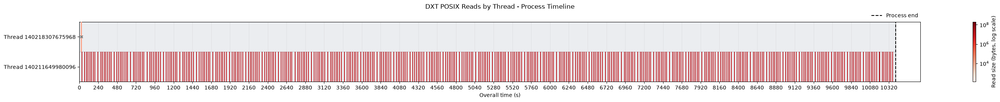

In [33]:
runtime = d["metadata"]["job"]["run_time"]

dataset_record = next(
    record for record in dxt_data
    if record["file_name"].endswith(".root")
)

reads = sorted(
    [row for row in dataset_record["rows"]
     if row["operation"] == "read"],
    key=lambda row: row["start_s"]
)

positive_lengths = [r["length"] for r in reads if r["length"] > 0]

norm = mcolors.LogNorm(
    vmin=min(positive_lengths),
    vmax=max(positive_lengths)
)

cmap = plt.get_cmap("Reds")

# Group reads by thread
thread_ids = sorted({str(r["pthread_id"]) for r in reads})
thread_reads = {
    tid: [r for r in reads if str(r["pthread_id"]) == tid]
    for tid in thread_ids
}

fig, ax = plt.subplots(figsize=(30, 2.8))

lane_height = 0.8

# Contiguous thread lanes
lane_bottoms = {
    tid: i * lane_height
    for i, tid in enumerate(thread_ids)
}

for tid in thread_ids:
    y0 = lane_bottoms[tid]

    # Full process duration background
    ax.broken_barh(
        [(0, runtime)],
        (y0, lane_height),
        facecolors="#ebedf0",
        edgecolors="#c8ccd1",
        zorder=1
    )

    # Read intervals
    for row in thread_reads[tid]:
        start = row["start_s"]
        end = row["end_s"]
        length = row["length"]
        duration = end - start

        if length == 0:
            ax.plot(
                start,
                y0 + lane_height / 2,
                "x",
                color="gray",
                markersize=5,
                zorder=5
            )
            continue

        color = cmap(norm(length))

        if duration > 0:
            ax.broken_barh(
                [(start, duration)],
                (y0, lane_height),
                facecolors=color,
                edgecolors="none",
                zorder=3
            )

        # Start marker for visibility
        ax.vlines(
            start,
            y0,
            y0 + lane_height,
            color=color,
            linewidth=1.2,
            zorder=4
        )

# Process end marker
ax.axvline(
    runtime,
    color="black",
    linestyle="--",
    label="Process end",
    zorder=6
)

ax.set_xlim(0, runtime * 1.03)
ax.set_ylim(0, lane_height * len(thread_ids))

# X-axis ticks every 5 seconds
ax.set_xticks(range(0, int(runtime) + 1, 240))

# Actual thread IDs
ax.set_yticks([
    lane_bottoms[tid] + lane_height / 2
    for tid in thread_ids
])
ax.set_yticklabels([
    f"Thread {tid}"
    for tid in thread_ids
])

ax.set_xlabel("Overall time (s)")
ax.set_title(
    "DXT POSIX Reads by Thread - Process Timeline",
    pad=25
)

ax.grid(axis="x", alpha=0.2)

# Logarithmic read-size colorbar
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Read size (bytes, log scale)")

# Legend outside the plotting area
ax.legend(
    loc="lower right",
    bbox_to_anchor=(1, 1.02),
    frameon=False,
    borderaxespad=0
)

plt.tight_layout()
plt.savefig(
    "dxt_two_thread_timeline_contiguous_root50.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

Selected application events: 106
   20.250s  main_start
   20.292s  train_start
   25.631s  loader_build_start
   25.631s  loader_build_end
   25.631s  epoch_start
  236.832s  epoch_end
  236.832s  epoch_start
  443.824s  epoch_end
  443.824s  epoch_start
  652.275s  epoch_end
  652.275s  epoch_start
  861.421s  epoch_end
  861.421s  epoch_start
 1071.584s  epoch_end
 1071.584s  epoch_start
 1281.336s  epoch_end
 1281.336s  epoch_start
 1492.083s  epoch_end
 1492.083s  epoch_start
 1702.794s  epoch_end
 1702.795s  epoch_start
 1911.723s  epoch_end
 1911.723s  epoch_start
 2120.555s  epoch_end
 2120.555s  epoch_start
 2329.151s  epoch_end
 2329.151s  epoch_start
 2538.346s  epoch_end
 2538.346s  epoch_start
 2748.103s  epoch_end
 2748.103s  epoch_start
 2957.878s  epoch_end
 2957.878s  epoch_start
 3167.350s  epoch_end
 3167.350s  epoch_start
 3378.017s  epoch_end
 3378.017s  epoch_start
 3587.034s  epoch_end
 3587.034s  epoch_start
 3796.256s  epoch_end
 3796.256s  epoch_start
 4006.56

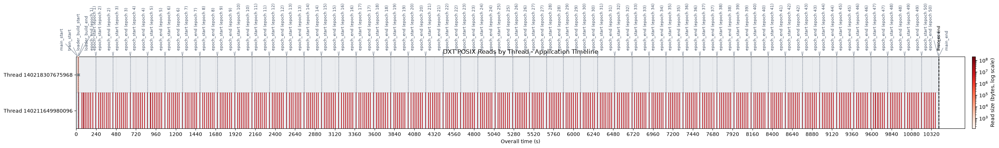

In [34]:
# ---------------------------------------------------------
# 1. Load and select application events
# ---------------------------------------------------------

LOG_PATH = Path('logs/root_stream_bim_2_shuffle_false_epochs_50_20261110_025958/logs/log.strategy_stream_bim_2_shuffle_false_batchsize_64_epochs_50.txt')
                
selected_event_names = {
    "main_start",
    "train_start",
    "loader_build_start",
    "loader_build_end",
    "epoch_start",
    "epoch_end",
    #"first_batch_received",
    #"first_batch_processed",
    #"batch_checkpoint",
    "train_end",
    "main_end",
}

job = d["metadata"]["job"]

darshan_start_ns = (
    int(job["start_time_sec"]) * 1_000_000_000
    + int(job["start_time_nsec"])
)

runtime = job["run_time"]

events = []

with LOG_PATH.open("r", encoding="utf-8") as f:
    for line in f:
        if not line.startswith("TRACE_EVENT "):
            continue

        event = json.loads(line[len("TRACE_EVENT "):])

        if event["event"] not in selected_event_names:
            continue

        event["time_s"] = (
            int(event["unix_ns"]) - darshan_start_ns
        ) / 1_000_000_000

        events.append(event)

events.sort(key=lambda e: e["time_s"])

if not events:
    raise ValueError("No selected TRACE_EVENT records were found.")

if any(e["time_s"] < 0 or e["time_s"] > runtime for e in events):
    raise ValueError(
        "Application events fall outside the Darshan runtime. "
        "Check that both files belong to the same execution."
    )

print(f"Selected application events: {len(events)}")

for event in events:
    print(f"{event['time_s']:9.3f}s  {event['event']}")


# ---------------------------------------------------------
# 2. Prepare DXT read operations
# ---------------------------------------------------------

dataset_record = next(
    record for record in dxt_data
    if record["file_name"].endswith("_2.root")
)

reads = sorted(
    [row for row in dataset_record["rows"]
     if row["operation"] == "read"],
    key=lambda row: row["start_s"]
)

positive_lengths = [r["length"] for r in reads if r["length"] > 0]

norm = mcolors.LogNorm(
    vmin=min(positive_lengths),
    vmax=max(positive_lengths)
)

cmap = plt.get_cmap("Reds")

thread_ids = sorted({str(r["pthread_id"]) for r in reads})

thread_reads = {
    tid: [r for r in reads if str(r["pthread_id"]) == tid]
    for tid in thread_ids
}


# ---------------------------------------------------------
# 3. Build contiguous thread lanes
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(30, 6))

lane_height = 0.8

lane_bottoms = {
    tid: i * lane_height
    for i, tid in enumerate(thread_ids)
}

for tid in thread_ids:
    y0 = lane_bottoms[tid]

    ax.broken_barh(
        [(0, runtime)],
        (y0, lane_height),
        facecolors="#ebedf0",
        edgecolors="#c8ccd1",
        zorder=1
    )

    for row in thread_reads[tid]:
        start = row["start_s"]
        end = row["end_s"]
        length = row["length"]
        duration = end - start

        if length == 0:
            ax.plot(
                start,
                y0 + lane_height / 2,
                "x",
                color="gray",
                markersize=5,
                zorder=5
            )
            continue

        color = cmap(norm(length))

        if duration > 0:
            ax.broken_barh(
                [(start, duration)],
                (y0, lane_height),
                facecolors=color,
                edgecolors="none",
                zorder=3
            )

        ax.vlines(
            start,
            y0,
            y0 + lane_height,
            color=color,
            linewidth=1.2,
            zorder=4
        )


# ---------------------------------------------------------
# 4. Application event lines
# ---------------------------------------------------------

event_line_color = "#475569"

for event in events:
    ax.axvline(
        event["time_s"],
        color=event_line_color,
        linestyle=":",
        linewidth=1,
        alpha=0.8,
        zorder=6
    )


# ---------------------------------------------------------
# 5. Process end
# ---------------------------------------------------------

ax.axvline(
    runtime,
    color="black",
    linestyle="--",
    linewidth=1.4,
    zorder=7
)


# ---------------------------------------------------------
# 6. Axes
# ---------------------------------------------------------

ax.set_xlim(0, runtime * 1.03)
ax.set_ylim(0, lane_height * len(thread_ids))

tick_step = (
    5 if runtime <= 600
    else 30 if runtime <= 3600
    else 120
)

ax.set_xticks(range(0, int(runtime) + 1, 240))

ax.set_yticks([
    lane_bottoms[tid] + lane_height / 2
    for tid in thread_ids
])

ax.set_yticklabels([
    f"Thread {tid}"
    for tid in thread_ids
])

ax.set_xlabel("Overall time (s)")
ax.set_title("DXT POSIX Reads by Thread - Application Timeline")

ax.grid(axis="x", alpha=0.2)


# ---------------------------------------------------------
# 7. Read-size colorbar
# ---------------------------------------------------------

sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    fraction=0.012,
    pad=0.008
)

cbar.set_label("Read size (bytes, log scale)")


# ---------------------------------------------------------
# 8. Vertical event labels above the plot
# ---------------------------------------------------------

# Leave sufficient room above the timeline
fig.subplots_adjust(
    left=0.12,
    right=0.95,
    bottom=0.14,
    top=0.47
)

fig.canvas.draw()

# Group labels that would overlap horizontally
# using their actual display positions
event_groups = []
current_group = []

min_spacing_px = 22

for event in events:
    x_px = ax.transData.transform((event["time_s"], 0))[0]

    if current_group and x_px - current_group[-1][1] >= min_spacing_px:
        event_groups.append(current_group)
        current_group = []

    current_group.append((event, x_px))

if current_group:
    event_groups.append(current_group)

# Place rotated labels with small horizontal offsets
# while keeping event lines at their true timestamps
for group in event_groups:
    n = len(group)

    for i, (event, _) in enumerate(group):
        label = event["event"]

        if "epoch" in event:
            label += f" (epoch {event['epoch']})"

        offset_pt = (i - (n - 1) / 2) * 16

        ax.annotate(
            label,
            xy=(event["time_s"], 1.0),
            xycoords=("data", "axes fraction"),
            xytext=(offset_pt, 12),
            textcoords="offset points",
            rotation=90,
            ha="center",
            va="bottom",
            fontsize=8,
            color=event_line_color,
            annotation_clip=False,
            arrowprops=dict(
                arrowstyle="-",
                color=event_line_color,
                linewidth=0.6
            )
        )

# Label the process end directly
ax.annotate(
    "Process end",
    xy=(runtime, 1.0),
    xycoords=("data", "axes fraction"),
    xytext=(0, 12),
    textcoords="offset points",
    rotation=90,
    ha="center",
    va="bottom",
    fontsize=8,
    color="black",
    annotation_clip=False
)


# ---------------------------------------------------------
# 9. Save
# ---------------------------------------------------------

plt.savefig(
    "dxt_threads_with_vertical_events50.png",
    dpi=180,
    bbox_inches="tight"
)

plt.savefig(
    "dxt_threads_with_vertical_events50.svg",
    bbox_inches="tight"
)

plt.show()